# Bài tập 02 - Hồi quy logistic

Chạy notebook từ thư mục gốc `02. Logistic_Regression`.


## Bài 1


In [1]:
# -*- coding: utf-8 -*-
"""Bài 1: thống kê tỷ lệ qua môn theo nhóm điểm giữa kỳ."""

import pandas as pd

df = pd.read_csv("data/sinh_vien.csv")
nhom_tu_7 = df[df["diem_giua_ky"] >= 7]
nhom_duoi_7 = df[df["diem_giua_ky"] < 7]

print("BAI 1: THONG KE THEO NHOM")
print("So ban co diem giua ky tu 7 tro len:", len(nhom_tu_7))
print(f"Ty le qua mon cua nhom tu 7 tro len: {nhom_tu_7['qua_mon'].mean():.4f}")
print(f"Ty le qua mon cua nhom con lai    : {nhom_duoi_7['qua_mon'].mean():.4f}")
print("Nhan xet: Diem giua ky phan biet hai nhom kha ro, vi ty le qua")
print("cua nhom tu 7 tro len cao hon nhieu so voi nhom con lai.")


BAI 1: THONG KE THEO NHOM
So ban co diem giua ky tu 7 tro len: 31
Ty le qua mon cua nhom tu 7 tro len: 0.9032
Ty le qua mon cua nhom con lai    : 0.4831
Nhan xet: Diem giua ky phan biet hai nhom kha ro, vi ty le qua
cua nhom tu 7 tro len cao hon nhieu so voi nhom con lai.


## Bài 2


Đã lưu biểu đồ tại: figures/sigmoid.png


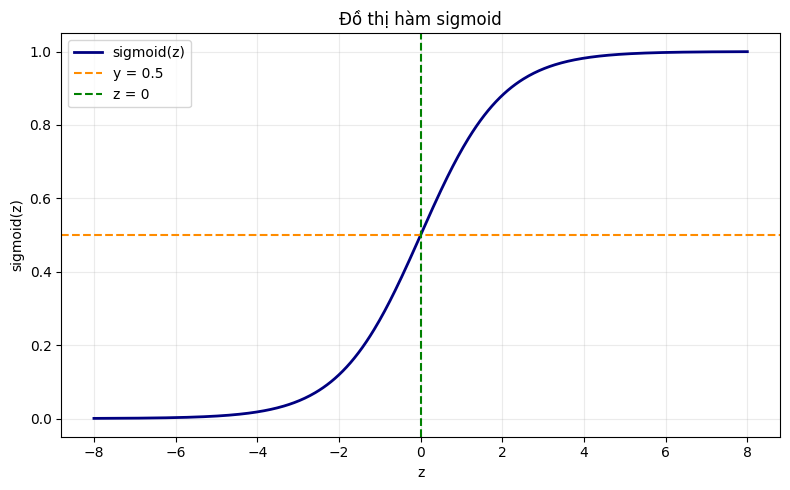

In [3]:
# BÀI 2: VẼ HÀM SIGMOID

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


# Hàm sigmoid
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# Tạo 500 giá trị z từ -8 đến 8
z = np.linspace(-8, 8, 500)
gia_tri_sigmoid = sigmoid(z)

# Vẽ đồ thị
plt.figure(figsize=(8, 5))

plt.plot(
    z,
    gia_tri_sigmoid,
    color="navy",
    linewidth=2,
    label="sigmoid(z)",
)

# Đường ngang tại y = 0.5
plt.axhline(
    y=0.5,
    color="darkorange",
    linestyle="--",
    label="y = 0.5",
)

# Đường dọc tại z = 0
plt.axvline(
    x=0,
    color="green",
    linestyle="--",
    label="z = 0",
)

plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Đồ thị hàm sigmoid")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

# Tự tạo thư mục figures nếu chưa tồn tại
thu_muc_hinh = Path("figures")
thu_muc_hinh.mkdir(parents=True, exist_ok=True)

# Lưu ảnh
duong_dan_hinh = thu_muc_hinh / "sigmoid.png"
plt.savefig(duong_dan_hinh, dpi=150, bbox_inches="tight")

print(f"Đã lưu biểu đồ tại: {duong_dan_hinh}")

# Hiển thị trong Colab
plt.show()

## Bài 3


In [4]:
# -*- coding: utf-8 -*-
"""Bài 3: dự đoán cho một sinh viên theo số giờ ôn."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]
mo_hinh = LogisticRegression().fit(X, y)

w = float(mo_hinh.coef_[0][0])
b = float(mo_hinh.intercept_[0])


def du_doan(gio):
    z = w * gio + b
    xac_suat = 1 / (1 + np.exp(-z))
    nhan = int(xac_suat >= 0.5)
    print(f"{gio:6.2f} gio | z = {z:+.4f} | p = {xac_suat:.4f} | nhan = {nhan}")


print("BAI 3: DU DOAN CHO MOT BAN CU THE")
print(f"w = {w:.6f}, b = {b:.6f}")
for gio in [3, 8, 12.89, 18, 26]:
    du_doan(gio)

print("\nGiai thich: moc chinh xac p = 0.5 la -b/w = " f"{-b / w:.4f} gio.")
print("12.89 chi la gia tri lam tron cua moc nay, nen p rat gan 0.5.")


BAI 3: DU DOAN CHO MOT BAN CU THE
w = 0.392819, b = -5.064890
  3.00 gio | z = -3.8864 | p = 0.0201 | nhan = 0
  8.00 gio | z = -1.9223 | p = 0.1276 | nhan = 0
 12.89 gio | z = -0.0015 | p = 0.4996 | nhan = 0
 18.00 gio | z = +2.0059 | p = 0.8814 | nhan = 1
 26.00 gio | z = +5.1484 | p = 0.9942 | nhan = 1

Giai thich: moc chinh xac p = 0.5 la -b/w = 12.8937 gio.
12.89 chi la gia tri lam tron cua moc nay, nen p rat gan 0.5.


## Bài 4


In [5]:
# -*- coding: utf-8 -*-
"""Bài 4: tự tính bốn thước đo từ TP, TN, FP, FN."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mo_hinh = LogisticRegression().fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

print("BAI 4: TU TINH BON THUOC DO")
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"Accuracy  = ({tp} + {tn}) / {tp + tn + fp + fn} = {accuracy:.4f}")
print(f"Precision = {tp} / ({tp} + {fp}) = {precision:.4f}")
print(f"Recall    = {tp} / ({tp} + {fn}) = {recall:.4f}")
print(f"F1        = 2*{precision:.4f}*{recall:.4f} / "
      f"({precision:.4f}+{recall:.4f}) = {f1:.4f}")
print("\nGiai thich: precision xet trong nhung ban bi doan la qua;")
print("recall xet trong nhung ban thuc su qua. F1 can bang hai dai luong nay.")


BAI 4: TU TINH BON THUOC DO
TN = 9, FP = 3, FN = 1, TP = 17
Accuracy  = (17 + 9) / 30 = 0.8667
Precision = 17 / (17 + 3) = 0.8500
Recall    = 17 / (17 + 1) = 0.9444
F1        = 2*0.8500*0.9444 / (0.8500+0.9444) = 0.8947

Giai thich: precision xet trong nhung ban bi doan la qua;
recall xet trong nhung ban thuc su qua. F1 can bang hai dai luong nay.


## Bài 5


In [6]:
# -*- coding: utf-8 -*-
"""Bài 5: dò ngưỡng có F1 cao nhất."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mo_hinh = LogisticRegression().fit(X_train, y_train)
p = mo_hinh.predict_proba(X_test)[:, 1]

ket_qua = []
print("BAI 5: DO NGUONG TOT NHAT THEO F1")
print("Nguong   F1")
for nguong in np.arange(0.05, 1.0, 0.05):
    y_pred = (p >= nguong).astype(int)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    ket_qua.append((float(nguong), float(f1)))
    print(f" {nguong:.2f}   {f1:.4f}")

f1_cao_nhat = max(f1 for _, f1 in ket_qua)
cac_nguong_tot = [n for n, f1 in ket_qua if np.isclose(f1, f1_cao_nhat)]
print(f"\nF1 cao nhat = {f1_cao_nhat:.4f}")
print("Cac nguong dat F1 cao nhat:", ", ".join(f"{n:.2f}" for n in cac_nguong_tot))
print("Chon nguong nho nhat trong cac nguong dong hang:", f"{cac_nguong_tot[0]:.2f}")
print("Nhan xet: nguong tot nhat theo F1 khong dung bang 0.5.")


BAI 5: DO NGUONG TOT NHAT THEO F1
Nguong   F1
 0.05   0.7826
 0.10   0.8182
 0.15   0.8182
 0.20   0.8571
 0.25   0.9000
 0.30   0.8947
 0.35   0.8947
 0.40   0.8947
 0.45   0.8947
 0.50   0.8947
 0.55   0.8889
 0.60   0.9412
 0.65   0.9412
 0.70   0.9091
 0.75   0.8750
 0.80   0.8387
 0.85   0.8000
 0.90   0.5600
 0.95   0.4348

F1 cao nhat = 0.9412
Cac nguong dat F1 cao nhat: 0.60, 0.65
Chon nguong nho nhat trong cac nguong dong hang: 0.60
Nhan xet: nguong tot nhat theo F1 khong dung bang 0.5.


## Bài 6


In [7]:
# -*- coding: utf-8 -*-
"""Bài 6: đổi lớp dương thành lớp rớt môn (lớp 0)."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/sinh_vien.csv")
X = df[["gio_on"]]
y = df["qua_mon"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
mo_hinh = LogisticRegression().fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

precision_1 = precision_score(y_test, y_pred, pos_label=1)
recall_1 = recall_score(y_test, y_pred, pos_label=1)
precision_0 = precision_score(y_test, y_pred, pos_label=0)
recall_0 = recall_score(y_test, y_pred, pos_label=0)

print("BAI 6: DOI LOP DUONG ROI CHAM LAI")
print(f"Lop qua mon (1): precision = {precision_1:.4f}, recall = {recall_1:.4f}")
print(f"Lop rot mon  (0): precision = {precision_0:.4f}, recall = {recall_0:.4f}")
print("\nGiai thich:")
print("Khi lop 1 la lop duong, precision va recall tap trung vao kha nang")
print("du doan va tim ra sinh vien qua mon. Khi doi lop 0 thanh lop duong,")
print("vai tro TP, FP, FN doi theo, nen mau so cua hai cong thuc cung doi.")
print("Vi vay hai bo so khac nhau du mo hinh va du lieu khong thay doi.")


BAI 6: DOI LOP DUONG ROI CHAM LAI
Lop qua mon (1): precision = 0.8500, recall = 0.9444
Lop rot mon  (0): precision = 0.9000, recall = 0.7500

Giai thich:
Khi lop 1 la lop duong, precision va recall tap trung vao kha nang
du doan va tim ra sinh vien qua mon. Khi doi lop 0 thanh lop duong,
vai tro TP, FP, FN doi theo, nen mau so cua hai cong thuc cung doi.
Vi vay hai bo so khac nhau du mo hinh va du lieu khong thay doi.
